In [6]:
import pandas as pd

df = pd.read_csv("/Iris.csv")

print("Dataset shape:", df.shape)
print("\nSpecies counts:")
print(df["Species"].value_counts())
print("\nFirst five rows:")
print(df.head())

Dataset shape: (150, 6)

Species counts:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

First five rows:
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa


Model Accuracy: 90.0 %

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.82      0.90      0.86        10
 Iris-virginica       0.89      0.80      0.84        10

       accuracy                           0.90        30
      macro avg       0.90      0.90      0.90        30
   weighted avg       0.90      0.90      0.90        30



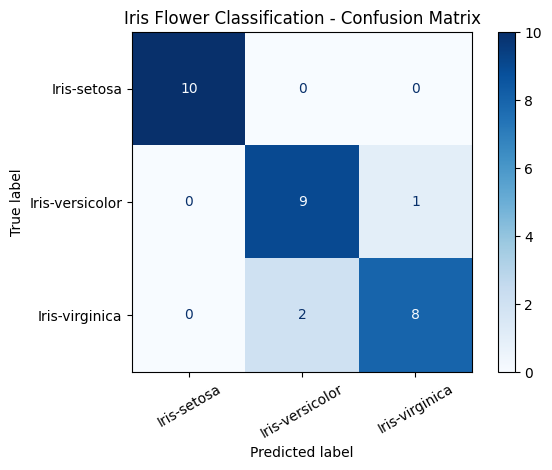

Sample flower prediction: Iris-setosa


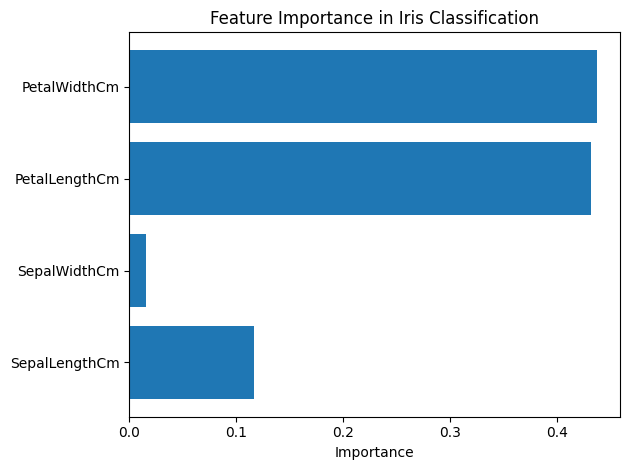

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# Load the dataset from the correct path
df = pd.read_csv("/Iris.csv")

# Select input features and target
X = df[[
    "SepalLengthCm",
    "SepalWidthCm",
    "PetalLengthCm",
    "PetalWidthCm"
]]
y = df["Species"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Create and train the model
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# Predict flower species
y_pred = model.predict(X_test)

# Display model performance
print("Model Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Display confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
display = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=model.classes_
)
display.plot(cmap="Blues", xticks_rotation=30)
plt.title("Iris Flower Classification - Confusion Matrix")
plt.tight_layout()
plt.show()

# Predict a new flower
sample = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=X.columns
)
print("Sample flower prediction:", model.predict(sample)[0])

# Feature importance graph
plt.barh(X.columns, model.feature_importances_)
plt.xlabel("Importance")
plt.title("Feature Importance in Iris Classification")
plt.tight_layout()
plt.show()

In [10]:

%%writefile main.py

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Load dataset
df = pd.read_csv("Iris.csv")

# Select features and target
features = [
    "SepalLengthCm",
    "SepalWidthCm",
    "PetalLengthCm",
    "PetalWidthCm"
]

X = df[features]
y = df["Species"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Train the model
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Display accuracy and classification report
print("IRIS FLOWER CLASSIFICATION")
print("-" * 35)
print(f"Model Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Save confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
display = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=model.classes_
)
display.plot(cmap="Blues", xticks_rotation=30)
plt.title("Iris Flower Classification - Confusion Matrix")
plt.tight_layout()
plt.savefig("/content/confusion_matrix.png", dpi=300)
plt.show()

# Save feature importance graph
plt.figure(figsize=(8, 5))
plt.barh(features, model.feature_importances_)
plt.xlabel("Importance")
plt.title("Feature Importance in Iris Classification")
plt.tight_layout()
plt.savefig("/content/feature_importance.png", dpi=300)
plt.show()

# Predict a sample flower
sample = pd.DataFrame([[5.1, 3.5, 1.4, 0.2]], columns=features)
print("Sample flower prediction:", model.predict(sample)[0])


Overwriting main.py


IRIS FLOWER CLASSIFICATION
-----------------------------------
Model Accuracy: 90.00%

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.82      0.90      0.86        10
 Iris-virginica       0.89      0.80      0.84        10

       accuracy                           0.90        30
      macro avg       0.90      0.90      0.90        30
   weighted avg       0.90      0.90      0.90        30



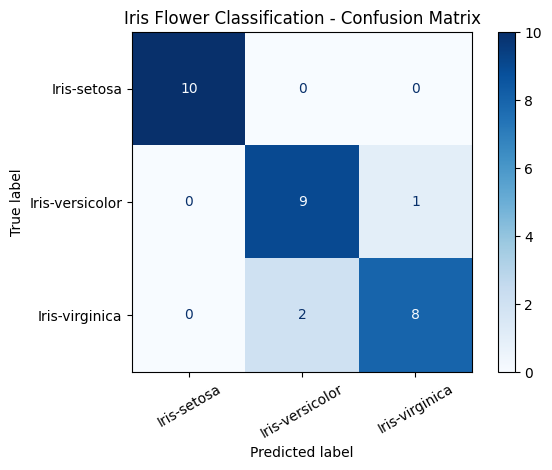

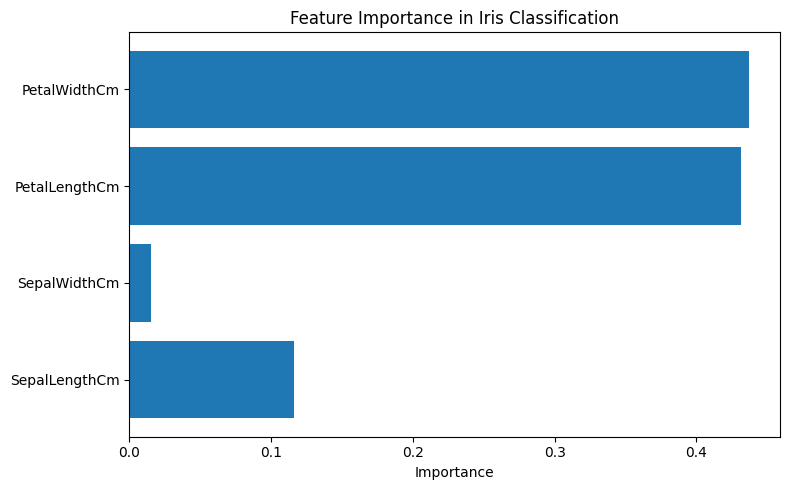

Sample flower prediction: Iris-setosa


<Figure size 640x480 with 0 Axes>

In [12]:
# Fix the path inside main.py to point to the correct file path /Iris.csv
with open('/content/main.py', 'r') as file:
    content = file.read()

content = content.replace('pd.read_csv("Iris.csv")', 'pd.read_csv("/Iris.csv")')

with open('/content/main.py', 'w') as file:
    file.write(content)

# Run the updated script
%run /content/main.py